In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

#data = yf.download(['SPY', 'AAPL', 'TSLA'], start='2015-02-01', end='2025-12-31')
#data.to_csv('raw_data.csv')

df = pd.read_csv('raw_data.csv', header=[0, 1], index_col=0, parse_dates=True)

In [11]:
import pandas as pd

# 1. Load bond data from local directory
bonds_df = pd.read_csv('data/raw/case_bonds.csv')
display(bonds_df.head())

# 2. Cash-Flow Matching Algorithm (Based on Exhibit 1 Data)
coupon_delta = 0.035  # Delta bond coupon: 3.50%
coupon_gamma = 0.040  # Gamma bond coupon: 4.00%
coupon_beta = 0.000   # Beta bond coupon: 0.00% (Zero-coupon)

# A. Match 2027 Obligation (Delta Bond - 5 Years)
need_2027 = 2400000
face_value_delta = need_2027 / (1 + coupon_delta)
coupon_payment_delta = face_value_delta * coupon_delta

# B. Match 2025 Obligation (Gamma Bond - 3 Years)
need_2025 = 1200000
# Subtract coupon received from Delta in 2025
shortfall_2025 = need_2025 - coupon_payment_delta 
face_value_gamma = shortfall_2025 / (1 + coupon_gamma)
coupon_payment_gamma = face_value_gamma * coupon_gamma

# C. Match 2024 Obligation (Beta Bond - 2 Years)
need_2024 = 2400000
# Subtract coupons received from both Delta and Gamma in 2024
shortfall_2024 = need_2024 - (coupon_payment_delta + coupon_payment_gamma)
face_value_beta = shortfall_2024 / (1 + coupon_beta) # Divided by 1.0 since it's zero-coupon

# 3. Calculate Portfolio Initial Cost
price_delta_per_1000 = 986.07
price_gamma_per_1000 = 1002.49
price_beta_per_1000 = 922.78

cost_delta = (face_value_delta / 1000) * price_delta_per_1000
cost_gamma = (face_value_gamma / 1000) * price_gamma_per_1000
cost_beta = (face_value_beta / 1000) * price_beta_per_1000
total_bond_portfolio_cost = cost_delta + cost_gamma + cost_beta

# Output results for Committee Memo
print("--- REQUIRED BOND FACE VALUES ---")
print(f"Delta (Maturity 2027): ${face_value_delta:,.2f}")
print(f"Gamma (Maturity 2025): ${face_value_gamma:,.2f}")
print(f"Beta (Maturity 2024):  ${face_value_beta:,.2f}")
print("\n--- INITIAL INVESTMENT COST ---")
print(f"Total Bond Portfolio Cost: ${total_bond_portfolio_cost:,.2f}")

,Bond,Maturity_Years,Annual_Coupon_Rate,Price,Face_Value
0,Alpha,1,0.000,958.77,1000
1,Beta,2,0.000,922.78,1000
2,Gamma,3,0.040,1002.49,1000
3,Delta,5,0.035,986.07,1000
4,Epsilon,8,0.045,1040.71,1000


--- REQUIRED BOND FACE VALUES ---
Delta (Maturity 2027): $2,318,840.58
Gamma (Maturity 2025): $1,075,808.25
Beta (Maturity 2024):  $2,275,808.25

--- INITIAL INVESTMENT COST ---
Total Bond Portfolio Cost: $5,465,096.48


In [15]:
import os
import numpy as np
import pandas as pd
import scipy.optimize as optimize
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)

# --- 3. YIELD, DURATION & CONVEXITY ---
cf_2023 = coupon_payment_gamma + coupon_payment_delta
cf_2024 = face_value_beta + coupon_payment_gamma + coupon_payment_delta 
cf_2025 = face_value_gamma + coupon_payment_gamma + coupon_payment_delta 
cf_2026 = coupon_payment_delta 
cf_2027 = face_value_delta + coupon_payment_delta 

cash_flows = [cf_2023, cf_2024, cf_2025, cf_2026, cf_2027]

def ytm_equation(y):
    return sum([cf / (1 + y)**(t + 1) for t, cf in enumerate(cash_flows)]) - total_bond_portfolio_cost

ytm = optimize.newton(ytm_equation, 0.05)

t_array = np.arange(1, 6) 
discounted_cf = np.array([cf / (1 + ytm)**t for t, cf in zip(t_array, cash_flows)])
mac_duration = np.sum(t_array * discounted_cf) / total_bond_portfolio_cost
mod_duration = mac_duration / (1 + ytm)
convexity = np.sum(t_array * (t_array + 1) * discounted_cf) / (total_bond_portfolio_cost * (1 + ytm)**2)

print("--- PORTFOLIO RISK METRICS (For Memo) ---")
print(f"Yield to Maturity (YTM): {ytm:.4%}")
print(f"Macaulay Duration:     {mac_duration:.4f} years")
print(f"Modified Duration:     {mod_duration:.4f} years")
print(f"Convexity:             {convexity:.4f}")

--- PORTFOLIO RISK METRICS (For Memo) ---
Yield to Maturity (YTM): 3.8960%
Macaulay Duration:     3.2877 years
Modified Duration:     3.1644 years
Convexity:             14.7965


<Figure size 800x500 with 0 Axes>

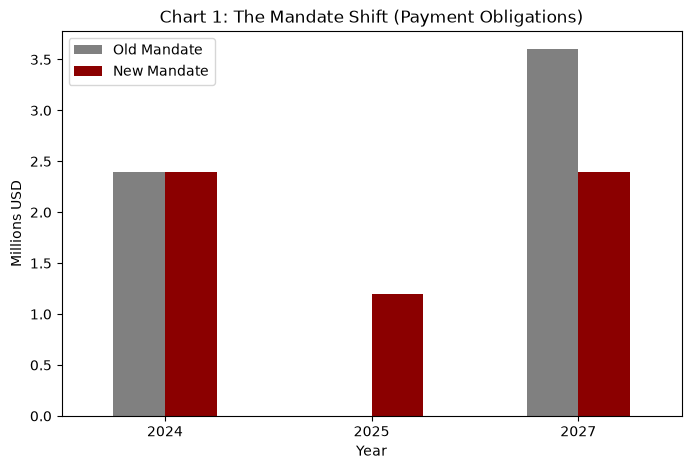

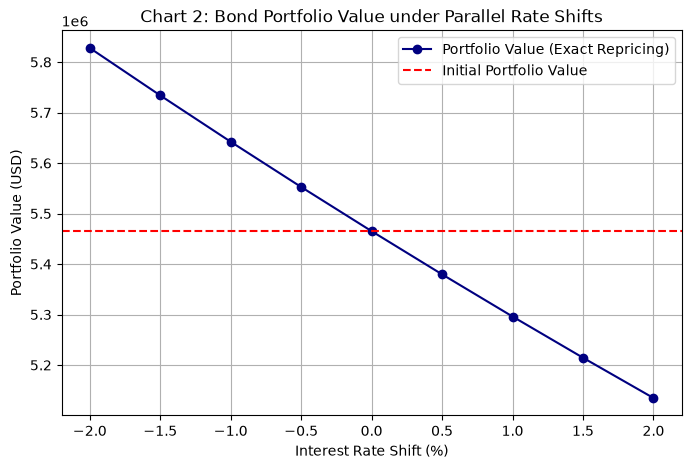

In [12]:
import os
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)

# --- CHART 1: The Mandate Shift ---
data_shift = {'Year': ['2024', '2025', '2027'],
              'Old Mandate': [2.4, 0, 3.6],
              'New Mandate': [2.4, 1.2, 2.4]}
df_shift = pd.DataFrame(data_shift)

plt.figure(figsize=(8, 5))
df_shift.plot(x='Year', kind='bar', color=['gray', 'darkred'], figsize=(8, 5))
plt.title('Chart 1: The Mandate Shift (Payment Obligations)')
plt.ylabel('Millions USD')
plt.xticks(rotation=0)
plt.savefig('outputs/mandate_shift_chart1.png', dpi=300, bbox_inches='tight')
plt.show()

# --- CHART 2: Bond Immunization & Rate Shift ---
rate_shifts = np.arange(-0.02, 0.025, 0.005) # Interest rate shift from -2% to +2%
portfolio_values = []

for shift in rate_shifts:
    new_ytm = ytm + shift
    pv_new = sum([cf / (1 + new_ytm)**(t + 1) for t, cf in enumerate(cash_flows)])
    portfolio_values.append(pv_new)

plt.figure(figsize=(8, 5))
plt.plot(rate_shifts * 100, portfolio_values, marker='o', color='navy', label='Portfolio Value (Exact Repricing)')
plt.axhline(y=total_bond_portfolio_cost, color='red', linestyle='--', label='Initial Portfolio Value')
plt.title('Chart 2: Bond Portfolio Value under Parallel Rate Shifts')
plt.xlabel('Interest Rate Shift (%)')
plt.ylabel('Portfolio Value (USD)')
plt.legend()
plt.grid(True)
plt.savefig('outputs/bond_immunization_chart2.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# --- SURPLUS CASH & COST CONSEQUENCES (For Memo) ---

# Calculate surplus cash from years with no obligation (2023 and 2026)
surplus_2023 = coupon_payment_gamma + coupon_payment_delta
surplus_2026 = coupon_payment_delta
total_surplus_cash = surplus_2023 + surplus_2026

# Compare with Old Mandate cost
old_mandate_bond_cost = 5532142.27 # From Initial Decision Record
cost_savings = old_mandate_bond_cost - total_bond_portfolio_cost

print("--- MANDATE CHANGE CONSEQUENCES ---")
print(f"Total Surplus Cash Retained (2023 & 2026): ${total_surplus_cash:,.2f}")
print(f"Old Mandate Bond Cost:                     ${old_mandate_bond_cost:,.2f}")
print(f"New Mandate Bond Cost:                     ${total_bond_portfolio_cost:,.2f}")
print(f"Extra Cash Available for Growth (SPY):     ${cost_savings:,.2f}")

--- MANDATE CHANGE CONSEQUENCES ---
Total Surplus Cash Retained (2023 & 2026): $205,351.17
Old Mandate Bond Cost:                     $5,532,142.27
New Mandate Bond Cost:                     $5,465,096.48
Extra Cash Available for Growth (SPY):     $67,045.79
